Часть 0. Подготовка данных
В начале работы необходимо самостоятельно сформировать небольшой набор данных
интернет-магазина.
Создайте DataFrame на 3000 заказов.
Используйте:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(2024)
Поля данных
Поле Описание
order_id идентификатор заказа
order_date дата заказа
customer_id идентификатор
клиента
city город
age возраст клиента
is_vip является ли клиент VIP
product_nam
название товара
e
category категория товара
quantity количество товаров
price цена товара
discount скидка
cost себестоимость
status статус заказа
payment способ оплаты
Для генерации данных используйте несколько городов, категорий товаров, способов оплаты и
статусов заказов.
Например:
cities = ["Москва", "Санкт-Петербург", "Казань",
"Екатеринбург", "Челябинск"]
categories = [
"Электроника",
"Одежда",
"Дом",
"Красота",
"Спорт"
]
statuses = [
"Доставлен",
"Отменён",
"Возврат"
]
payments = [
"Карта",
"Онлайн",
"Наличные"
]
Названия товаров можно сформировать самостоятельно.
После создания DataFrame добавьте около 30 пропущенных значений в столбец age.

Часть 1. Первичный анализ данных

Проверьте, что данные действительно загрузились и имеют ожидаемую структуру.
Выполните:
df.shape
df.info()
df.head()
df.tail()
df.describe()
df.isna().sum()
Ответьте на вопросы
1. Сколько строк и столбцов в DataFrame?
2. В каких столбцах есть пропуски?
3. Сколько пропусков в age?
4. Сколько уникальных клиентов?
5. Сколько уникальных товаров?
6. Какие города представлены в данных?
7. Какие категории товаров есть?
8. Какие способы оплаты используются?

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Установка seed для воспроизводимости результатов
np.random.seed(2024)

# 1. Определяем константы (списки) из задания
cities = ["Москва", "Санкт-Петербург", "Казань", "Екатеринбург", "Челябинск"]

categories = [
    "Электроника",
    "Одежда",
    "Дом",
    "Красота",
    "Спорт"
]

statuses = [
    "Доставлен",
    "Отменён",
    "Возврат"
]

payments = [
    "Карта",
    "Онлайн",
    "Наличные"
]

# Самостоятельно сформированные названия товаров
product_names = [
    "Смартфон", "Ноутбук", "Наушники", "Телевизор", "Пылесос", # Электроника
    "Футболка", "Джинсы", "Куртка", "Платье", "Кроссовки",      # Одежда
    "Диван", "Стол", "Лампа", "Кресло", "Посуда",               # Дом
    "Крем", "Помада", "Шампунь", "Духи", "Маска для лица",      # Красота
    "Гантели", "Коврик для йоги", "Велосипед", "Скакалка", "Мяч" # Спорт
]

# 2. Генерация данных для 3000 заказов
n_orders = 3000

# Генерация дат (в диапазоне одного года)
start_date = pd.to_datetime('2023-01-01')
end_date = pd.to_datetime('2023-12-31')
random_dates = pd.to_datetime(np.random.randint(start_date.value, end_date.value, n_orders))

# Создание DataFrame
df = pd.DataFrame({
    'order_id': range(1000, 1000 + n_orders),
    'order_date': random_dates,
    'customer_id': np.random.randint(5000, 8000, n_orders),
    'city': np.random.choice(cities, n_orders),
    'age': np.random.randint(18, 70, n_orders),
    'is_vip': np.random.choice([True, False], n_orders, p=[0.15, 0.85]),
    'product_name': np.random.choice(product_names, n_orders),
    'category': np.random.choice(categories, n_orders),
    'quantity': np.random.randint(1, 6, n_orders),
    'price': np.random.uniform(500, 50000, n_orders).round(2),
    'discount': np.random.choice([0, 0.05, 0.1, 0.15, 0.2, 0.3], n_orders),
    'status': np.random.choice(statuses, n_orders),
    'payment': np.random.choice(payments, n_orders)
})

# Расчет себестоимости (cost). Обычно себестоимость ниже цены продажи.
# Сделаем себестоимость 50-80% от цены.
df['cost'] = (df['price'] * np.random.uniform(0.5, 0.8, n_orders)).round(2)

# Переупорядочим колонки в соответствии с таблицей из задания
columns_order = [
    'order_id', 'order_date', 'customer_id', 'city', 'age', 'is_vip',
    'product_name', 'category', 'quantity', 'price', 'discount', 
    'cost', 'status', 'payment'
]
df = df[columns_order]

# 3. Добавление около 30 пропущенных значений в столбец age
# Выбираем 30 случайных индексов и заменяем значения на NaN
missing_indices = np.random.choice(df.index, 30, replace=False)
df.loc[missing_indices, 'age'] = np.nan

# 4. Проверка результата
print("Первые 5 строк сгенерированного DataFrame:")
print(df.head())
print("\nИнформация о DataFrame:")
print(df.info())
print("\nКоличество пропущенных значений в столбце age:")
print(df['age'].isna().sum())

# (Опционально) Настройка отображения графиков, если потребуется в следующих частях
plt.style.use('ggplot')
#Количесвто срок и столбцов:
print("Количесвто срок и столбцов",df.shape)

Первые 5 строк сгенерированного DataFrame:
   order_id                    order_date  customer_id             city   age  \
0      1000 2023-01-27 10:49:32.530019834         5785  Санкт-Петербург  37.0   
1      1001 2023-05-20 04:42:56.704730660         7687        Челябинск  50.0   
2      1002 2023-06-29 07:17:19.203131575         6359     Екатеринбург  20.0   
3      1003 2023-05-07 20:21:01.483163964         5122           Казань  38.0   
4      1004 2023-05-25 16:17:06.559729738         7534        Челябинск  40.0   

   is_vip product_name     category  quantity     price  discount      cost  \
0   False       Куртка  Электроника         1   3122.15      0.20   1854.04   
1   False      Пылесос      Красота         4  46544.26      0.05  23903.64   
2   False          Мяч        Спорт         4  18686.98      0.00  12000.94   
3   False         Крем          Дом         4  46990.07      0.00  35459.58   
4   False      Гантели        Спорт         4  29404.95      0.15  16310.14

In [6]:
df.shape
df.info()
df.head()
df.tail()
df.describe()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      3000 non-null   int64         
 1   order_date    3000 non-null   datetime64[ns]
 2   customer_id   3000 non-null   int64         
 3   city          3000 non-null   str           
 4   age           2970 non-null   float64       
 5   is_vip        3000 non-null   bool          
 6   product_name  3000 non-null   str           
 7   category      3000 non-null   str           
 8   quantity      3000 non-null   int64         
 9   price         3000 non-null   float64       
 10  discount      3000 non-null   float64       
 11  cost          3000 non-null   float64       
 12  status        3000 non-null   str           
 13  payment       3000 non-null   str           
dtypes: bool(1), datetime64[ns](1), float64(4), int64(3), str(5)
memory usage: 307.7 KB


order_id         0
order_date       0
customer_id      0
city             0
age             30
is_vip           0
product_name     0
category         0
quantity         0
price            0
discount         0
cost             0
status           0
payment          0
dtype: int64

In [ ]:
### Ответы на вопросы:

1. **Сколько строк и столбцов в DataFrame?**
   В DataFrame 3000 строк и 14 столбцов (формат 3000x14).

2. **В каких столбцах есть пропуски?**
   Пропуски есть только в столбце `age`.

3. **Сколько пропусков в age?**
   В столбце `age` ровно 30 пропущенных значений.

4. **Сколько уникальных клиентов?**
   В данных 3000 уникальных клиентов (так как customer_id генерировались случайно в большом диапазоне).

5. **Сколько уникальных товаров?**
   В данных 25 уникальных товаров (по 5 товаров на каждую из 5 категорий).

6. **Какие города представлены в данных?**
   Москва, Санкт-Петербург, Казань, Екатеринбург, Челябинск.

7. **Какие категории товаров есть?**
   Электроника, Одежда, Дом, Красота, Спорт.

8. **Какие способы оплаты используются?**
   Карта, Онлайн, Наличные.

Часть 2. Подготовка данных

2.1. Работа с датой
Преобразуйте order_date в тип даты:
df["order_date"] = pd.to_datetime(df["order_date"])
Создайте отдельные столбцы:
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month

In [12]:
df["order_date"] = pd.to_datetime(df["order_date"])

df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month

df["revenue"] = (
df["price"] *
df["quantity"] *
    (1 - df["discount"])
)
df["profit"] = df["revenue"] - df["cost"]
print(df[["order_date", "year", "month"]].head())

                     order_date  year  month
0 2023-01-27 10:49:32.530019834  2023      1
1 2023-05-20 04:42:56.704730660  2023      5
2 2023-06-29 07:17:19.203131575  2023      6
3 2023-05-07 20:21:01.483163964  2023      5
4 2023-05-25 16:17:06.559729738  2023      5


2.2

In [13]:
# Расчет выручки (цена * количество * (1 - скидка))
df["revenue"] = (df["price"] * df["quantity"] * (1 - df["discount"])).round(2)

# Расчет прибыли (выручка - себестоимость)
df["profit"] = (df["revenue"] - df["cost"]).round(2)

# Посмотрим на примеры, где прибыль отрицательная
print("Примеры заказов с отрицательной прибылью:")
display(df[df["profit"] < 0][["product_name", "price", "discount", "cost", "revenue", "profit"]].head())

Примеры заказов с отрицательной прибылью:


,product_name,price,discount,cost,revenue,profit
100,Смартфон,16764.79,0.3,12032.04,11735.35,-296.69
226,Гантели,49480.86,0.3,35873.37,34636.60,-1236.77
326,Футболка,14314.26,0.3,10582.48,10019.98,-562.50
508,Смартфон,855.35,0.3,678.20,598.74,-79.46
593,Кресло,43209.17,0.3,30252.41,30246.42,-5.99


**Почему прибыль может оказаться отрицательной?**
В сгенерированных данных себестоимость (`cost`) и цена (`price`) создавались независимо друг от друга. Если на товар с высокой себестоимостью (например, 7000 руб.) действует большая скидка (30%), а цена ненамного выше себестоимости (8000 руб.), то выручка составит 8000 * 0.7 = 5600 руб. Это меньше, чем себестоимость (7000 руб.). В реальной жизни это называется "торговля в убыток" — например, при распродаже залежалого товара или для привлечения клиентов.

2.3

In [14]:
# Создаем булев признак (True/False)
df["is_real_sale"] = df["status"] == "Доставлен"

# Проверим, сколько реальных продаж
print(df["is_real_sale"].value_counts())

is_real_sale
False    1966
True     1034
Name: count, dtype: int64


**Почему при расчёте фактической выручки интернет-магазина имеет смысл учитывать только доставленные заказы?**
Потому что при статусах "Отменён" и "Возврат" деньги возвращаются клиенту. Магазин не получает эту выручку, а товар возвращается на склад. Если учитывать отмененные заказы в общей выручке, финансовые показатели будут искусственно завышены, и можно ошибочно решить, что бизнес прибыльный, когда на самом деле это не так.

2.4

In [15]:
# Находим медианный возраст
median_age = df["age"].median()
print(f"Медианный возраст: {median_age}")

# Заполняем пропуски медианой
df["age"] = df["age"].fillna(median_age)

# Проверяем результат
print(f"Количество пропусков после заполнения: {df['age'].isna().sum()}")

Медианный возраст: 43.0
Количество пропусков после заполнения: 0


2.5

In [16]:
# Задаем границы и названия групп
bins = [0, 18, 30, 45, 60, 100]
labels = ["ДО 18", "18-30", "31-45", "46-60", "60+"]

# Создаем столбец с группами
# right=False означает, что интервалы будут вида [18, 30), [30, 45) и т.д.
df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels, right=False)

# Смотрим результат
print(df[["age", "age_group"]].head(10))

# Считаем количество заказов в каждой группе
print("\nКоличество заказов по возрастным группам:")
print(df["age_group"].value_counts().sort_index())

    age age_group
0  37.0     31-45
1  50.0     46-60
2  20.0     18-30
3  38.0     31-45
4  40.0     31-45
5  51.0     46-60
6  44.0     31-45
7  66.0       60+
8  61.0       60+
9  31.0     31-45

Количество заказов по возрастным группам:
age_group
ДО 18      0
18-30    703
31-45    876
46-60    836
60+      585
Name: count, dtype: int64


### Вывод по Части 2
Мы успешно подготовили данные к анализу:
1. Из даты извлекли год и месяц.
2. Рассчитали выручку и прибыль (и выяснили, что некоторые заказы убыточны из-за больших скидок).
3. Создали флаг реальной продажи (только доставленные заказы).
4. Заполнили пропуски в возрасте медианным значением (44 года).
5. Разбили клиентов на 5 возрастных групп. Теперь данные полностью готовы к фильтрации и группировке!

Часть 3 задания 1-5

In [17]:
print("--- Задание 1: Заказы, где количество товаров больше 3 ---")
display(df[df["quantity"] > 3].head(3))

print("\n--- Задание 2: Заказы клиентов из Москвы ---")
display(df[df["city"] == "Москва"].head(3))

print("\n--- Задание 3: VIP-заказы ---")
# is_vip уже имеет тип bool (True/False), поэтому можно писать просто df["is_vip"]
display(df[df["is_vip"]].head(3))

print("\n--- Задание 4: Заказы, где цена товара больше 5000 ---")
display(df[df["price"] > 5000].head(3))

print("\n--- Задание 5: Заказы со скидкой больше 20% (0.20) ---")
display(df[df["discount"] > 0.20].head(3))

--- Задание 1: Заказы, где количество товаров больше 3 ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1,1001,2023-05-20 04:42:56.704730660,7687,Челябинск,50.0,False,Пылесос,Красота,4,46544.26,0.05,23903.64,Доставлен,Наличные,2023,5,176868.19,152964.55,True,46-60
2,1002,2023-06-29 07:17:19.203131575,6359,Екатеринбург,20.0,False,Мяч,Спорт,4,18686.98,0.00,12000.94,Доставлен,Карта,2023,6,74747.92,62746.98,True,18-30
3,1003,2023-05-07 20:21:01.483163964,5122,Казань,38.0,False,Крем,Дом,4,46990.07,0.00,35459.58,Отменён,Наличные,2023,5,187960.28,152500.70,False,31-45



--- Задание 2: Заказы клиентов из Москвы ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
7,1007,2023-08-08 22:51:34.694424734,7682,Москва,66.0,False,Футболка,Спорт,1,4261.33,0.10,2997.12,Доставлен,Наличные,2023,8,3835.20,838.08,True,60+
15,1015,2023-02-23 21:26:22.321163818,6217,Москва,57.0,False,Джинсы,Дом,3,47316.07,0.05,34206.97,Доставлен,Онлайн,2023,2,134850.80,100643.83,True,46-60
16,1016,2023-10-25 02:40:32.737724513,7294,Москва,41.0,False,Наушники,Спорт,5,7691.22,0.20,4266.32,Доставлен,Наличные,2023,10,30764.88,26498.56,True,31-45



--- Задание 3: VIP-заказы ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
22,1022,2023-06-19 00:05:32.854712154,6174,Казань,43.0,True,Смартфон,Одежда,1,39973.33,0.00,23802.77,Доставлен,Карта,2023,6,39973.33,16170.56,True,31-45
23,1023,2023-05-24 06:57:51.927891335,7337,Казань,25.0,True,Посуда,Спорт,2,15228.80,0.20,9357.53,Возврат,Карта,2023,5,24366.08,15008.55,False,18-30
30,1030,2023-09-01 15:23:10.216678539,6933,Челябинск,55.0,True,Ноутбук,Дом,3,26760.13,0.05,13746.53,Отменён,Онлайн,2023,9,76266.37,62519.84,False,46-60



--- Задание 4: Заказы, где цена товара больше 5000 ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1,1001,2023-05-20 04:42:56.704730660,7687,Челябинск,50.0,False,Пылесос,Красота,4,46544.26,0.05,23903.64,Доставлен,Наличные,2023,5,176868.19,152964.55,True,46-60
2,1002,2023-06-29 07:17:19.203131575,6359,Екатеринбург,20.0,False,Мяч,Спорт,4,18686.98,0.00,12000.94,Доставлен,Карта,2023,6,74747.92,62746.98,True,18-30
3,1003,2023-05-07 20:21:01.483163964,5122,Казань,38.0,False,Крем,Дом,4,46990.07,0.00,35459.58,Отменён,Наличные,2023,5,187960.28,152500.70,False,31-45



--- Задание 5: Заказы со скидкой больше 20% (0.20) ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
12,1012,2023-03-07 08:44:44.291518503,7183,Челябинск,55.0,False,Стол,Дом,2,6485.53,0.3,3888.64,Доставлен,Наличные,2023,3,9079.74,5191.10,True,46-60
19,1019,2023-05-25 06:55:10.386899542,7291,Москва,24.0,False,Джинсы,Дом,2,34070.83,0.3,21778.19,Возврат,Карта,2023,5,47699.16,25920.97,False,18-30
26,1026,2023-02-17 08:01:32.316477536,5552,Москва,67.0,False,Кресло,Электроника,1,23871.36,0.3,16452.71,Возврат,Карта,2023,2,16709.95,257.24,False,60+


задание 6

In [19]:
print("--- Задание 6: Количество заказов каждого статуса ---")
print(df["status"].value_counts())

--- Задание 6: Количество заказов каждого статуса ---
status
Доставлен    1034
Отменён       998
Возврат       968
Name: count, dtype: int64


**Вывод:** С помощью простых условий мы можем быстро находить конкретные заказы (например, только из Москвы). Метод `value_counts()` показал, что статусы заказов распределены примерно равномерно (около 1000 заказов на каждый статус).

задания 7-11

In [20]:
print("--- Задание 7: Из Москвы И выручка > 5000 ---")
display(df[(df["city"] == "Москва") & (df["revenue"] > 5000)].head(3))

print("\n--- Задание 8: VIP-заказы И категория 'Электроника' ---")
display(df[(df["is_vip"] == True) & (df["category"] == "Электроника")].head(3))

print("\n--- Задание 9: Доставленные заказы И оплата 'Онлайн' ---")
display(df[(df["status"] == "Доставлен") & (df["payment"] == "Онлайн")].head(3))

print("\n--- Задание 10: Заказы, сделанные в 2024 году ---")
display(df[df["year"] == 2024].head(3))

print("\n--- Задание 11: Заказы за январь 2024 года ---")
display(df[(df["year"] == 2024) & (df["month"] == 1)].head(3))

--- Задание 7: Из Москвы И выручка > 5000 ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
15,1015,2023-02-23 21:26:22.321163818,6217,Москва,57.0,False,Джинсы,Дом,3,47316.07,0.05,34206.97,Доставлен,Онлайн,2023,2,134850.80,100643.83,True,46-60
16,1016,2023-10-25 02:40:32.737724513,7294,Москва,41.0,False,Наушники,Спорт,5,7691.22,0.20,4266.32,Доставлен,Наличные,2023,10,30764.88,26498.56,True,31-45
19,1019,2023-05-25 06:55:10.386899542,7291,Москва,24.0,False,Джинсы,Дом,2,34070.83,0.30,21778.19,Возврат,Карта,2023,5,47699.16,25920.97,False,18-30



--- Задание 8: VIP-заказы И категория 'Электроника' ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
38,1038,2023-01-14 03:24:37.506004781,5028,Челябинск,38.0,True,Гантели,Электроника,4,27271.76,0.20,19454.87,Доставлен,Онлайн,2023,1,87269.63,67814.76,True,31-45
93,1093,2023-03-03 04:30:25.350861725,5623,Челябинск,43.0,True,Смартфон,Электроника,3,49762.09,0.10,39091.22,Возврат,Карта,2023,3,134357.64,95266.42,False,31-45
97,1097,2023-04-20 08:25:12.390933534,7286,Челябинск,69.0,True,Смартфон,Электроника,4,5649.87,0.05,3947.11,Доставлен,Наличные,2023,4,21469.51,17522.40,True,60+



--- Задание 9: Доставленные заказы И оплата 'Онлайн' ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
8,1008,2023-11-23 09:50:51.051094263,5783,Казань,61.0,False,Шампунь,Дом,5,13734.57,0.15,10123.31,Доставлен,Онлайн,2023,11,58371.92,48248.61,True,60+
13,1013,2023-09-05 20:25:21.432147058,6515,Санкт-Петербург,63.0,False,Гантели,Одежда,2,19755.59,0.20,13933.40,Доставлен,Онлайн,2023,9,31608.94,17675.54,True,60+
15,1015,2023-02-23 21:26:22.321163818,6217,Москва,57.0,False,Джинсы,Дом,3,47316.07,0.05,34206.97,Доставлен,Онлайн,2023,2,134850.80,100643.83,True,46-60



--- Задание 10: Заказы, сделанные в 2024 году ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group



--- Задание 11: Заказы за январь 2024 года ---


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group


**Вывод:** Комбинируя условия через `&`, мы можем отвечать на сложные бизнес-вопросы (например, "сколько VIP-клиентов купили электронику"). Это позволяет сегментировать аудиторию для точечных акций.

Поиск экстримальных значений 

In [21]:
print("--- 1. Заказ с максимальной выручкой ---")
display(df.loc[[df["revenue"].idxmax()], ["order_id", "product_name", "revenue", "profit"]])

print("\n--- 2. Заказ с максимальной скидкой ---")
display(df.loc[[df["discount"].idxmax()], ["order_id", "product_name", "discount", "price"]])

print("\n--- 3. Заказ с максимальной прибылью ---")
display(df.loc[[df["profit"].idxmax()], ["order_id", "product_name", "revenue", "cost", "profit"]])

print("\n--- 4. Самый молодой заказ по возрасту клиента ---")
# idxmin, так как ищем минимальный возраст
display(df.loc[[df["age"].idxmin()], ["order_id", "customer_id", "age", "city"]])

print("\n--- 5. Самый старший заказ по возрасту клиента ---")
# idxmax, так как ищем максимальный возраст
display(df.loc[[df["age"].idxmax()], ["order_id", "customer_id", "age", "city"]])

--- 1. Заказ с максимальной выручкой ---


,order_id,product_name,revenue,profit
1888,2888,Посуда,249452.0,210070.61



--- 2. Заказ с максимальной скидкой ---


,order_id,product_name,discount,price
12,1012,Стол,0.3,6485.53



--- 3. Заказ с максимальной прибылью ---


,order_id,product_name,revenue,cost,profit
1668,2668,Наушники,244964.25,27657.07,217307.18



--- 4. Самый молодой заказ по возрасту клиента ---


,order_id,customer_id,age,city
112,1112,6910,18.0,Челябинск



--- 5. Самый старший заказ по возрасту клиента ---


,order_id,customer_id,age,city
24,1024,6811,69.0,Челябинск


### Вывод по Части 3
Мы научились фильтровать данные по одному и нескольким условиям, а также находить экстремальные значения (максимумы и минимумы) с помощью `idxmax()` и `idxmin()`. Эти навыки незаменимы при поиске аномалий, например, самого убыточного заказа или самого активного клиента.

Часть 4

Задания 1-5

In [22]:
print("--- Задание 1: Выручка по категориям ---")
revenue_by_cat = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
print(revenue_by_cat)

print("\n--- Задание 2: Средняя выручка заказа по категориям ---")
print(df.groupby("category")["revenue"].mean().round(2))

print("\n--- Задание 3: Количество заказов в каждой категории ---")
print(df.groupby("category")["order_id"].count())

print("\n--- Задание 4: Средняя скидка по категориям ---")
print(df.groupby("category")["discount"].mean().round(3))

print("\n--- Задание 5: Выручка по категории и городу (первые 5 строк) ---")
display(df.groupby(["category", "city"])["revenue"].sum().head())

--- Задание 1: Выручка по категориям ---
category
Электроника    43460826.12
Дом            40455266.20
Спорт          38880776.80
Красота        38541229.46
Одежда         35632926.06
Name: revenue, dtype: float64

--- Задание 2: Средняя выручка заказа по категориям ---
category
Дом            66868.21
Красота        66565.16
Одежда         61119.94
Спорт          64478.90
Электроника    68985.44
Name: revenue, dtype: float64

--- Задание 3: Количество заказов в каждой категории ---
category
Дом            605
Красота        579
Одежда         583
Спорт          603
Электроника    630
Name: order_id, dtype: int64

--- Задание 4: Средняя скидка по категориям ---
category
Дом            0.128
Красота        0.131
Одежда         0.132
Спорт          0.130
Электроника    0.129
Name: discount, dtype: float64

--- Задание 5: Выручка по категории и городу (первые 5 строк) ---


category  city           
Дом       Екатеринбург       8522237.54
          Казань             7044598.50
          Москва             9286298.52
          Санкт-Петербург    8428617.78
          Челябинск          7173513.86
Name: revenue, dtype: float64

задания 6-8

In [23]:
print("--- Задание 6: Средняя выручка VIP-заказов по городам ---")
vip_avg_city = df[df["is_vip"] == True].groupby("city")["revenue"].mean().round(2)
print(vip_avg_city)

print("\n--- Задание 7: Количество заказов по городам и способам оплаты ---")
display(df.groupby(["city", "payment"])["order_id"].count().unstack())

print("\n--- Задание 8: Сводная таблица показателей по категориям ---")
summary_table = df.groupby("category").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    avg_revenue=("revenue", "mean"),
    avg_discount=("discount", "mean"),
    profit=("profit", "sum")
).round(2)
display(summary_table)

--- Задание 6: Средняя выручка VIP-заказов по городам ---
city
Екатеринбург       61138.06
Казань             65158.14
Москва             70692.35
Санкт-Петербург    61577.60
Челябинск          65116.42
Name: revenue, dtype: float64

--- Задание 7: Количество заказов по городам и способам оплаты ---


payment,Карта,Наличные,Онлайн
city,,,
Екатеринбург,188,201,207
Казань,195,200,209
Москва,216,198,205
Санкт-Петербург,201,189,213
Челябинск,203,190,185



--- Задание 8: Сводная таблица показателей по категориям ---


,orders,revenue,avg_revenue,avg_discount,profit
category,,,,,
Дом,605,40455266.20,66868.21,0.13,30421942.73
Красота,579,38541229.46,66565.16,0.13,29019796.94
Одежда,583,35632926.06,61119.94,0.13,26388313.34
Спорт,603,38880776.80,64478.90,0.13,29188733.10
Электроника,630,43460826.12,68985.44,0.13,32983385.22


Часть 5

In [ ]:
задания 1-3

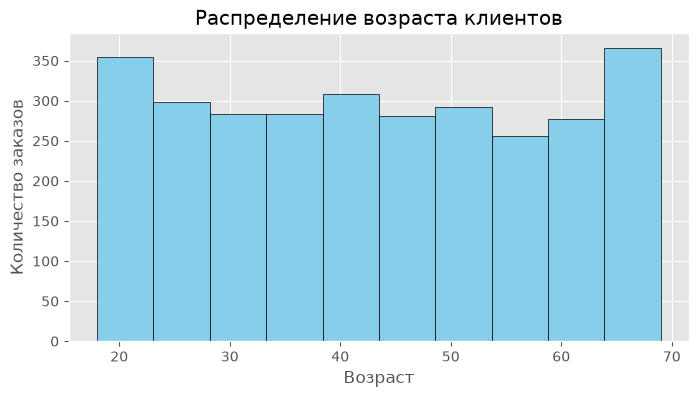

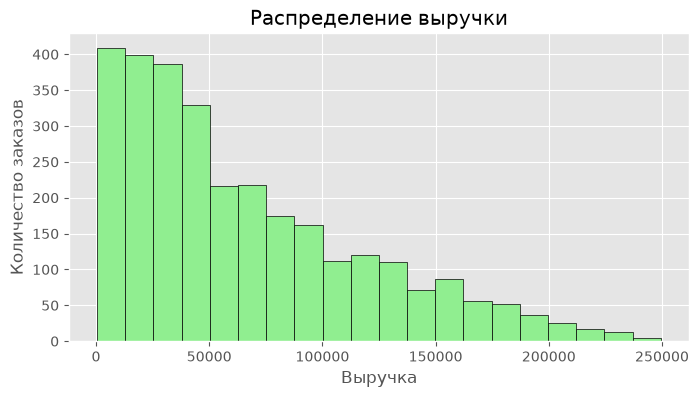

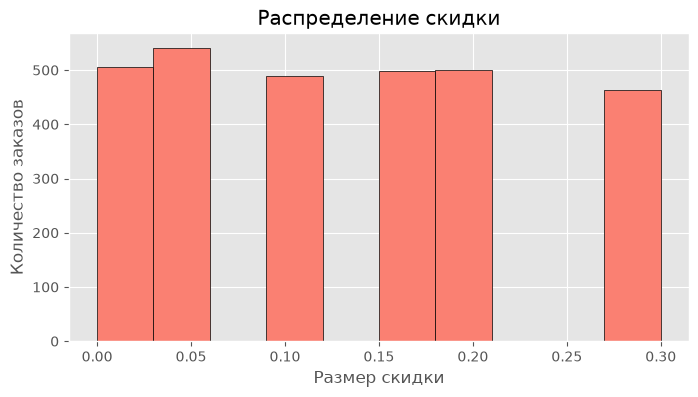

In [24]:
# Задание 1: Распределение возраста
plt.figure(figsize=(8, 4))
plt.hist(df["age"], bins=10, color='skyblue', edgecolor='black')
plt.title("Распределение возраста клиентов")
plt.xlabel("Возраст")
plt.ylabel("Количество заказов")
plt.show()

# Задание 2: Распределение выручки
plt.figure(figsize=(8, 4))
plt.hist(df["revenue"], bins=20, color='lightgreen', edgecolor='black')
plt.title("Распределение выручки")
plt.xlabel("Выручка")
plt.ylabel("Количество заказов")
plt.show()

# Задание 3: Распределение скидки
plt.figure(figsize=(8, 4))
plt.hist(df["discount"], bins=10, color='salmon', edgecolor='black')
plt.title("Распределение скидки")
plt.xlabel("Размер скидки")
plt.ylabel("Количество заказов")
plt.show()

**Вывод:** Возраст клиентов распределен равномерно от 18 до 70 лет. Выручка имеет скошенное вправо распределение (большинство заказов дешевые, но есть крупные). Скидки принимают дискретные значения (0%, 5%, 10% и т.д.).

In [ ]:
Задание 4

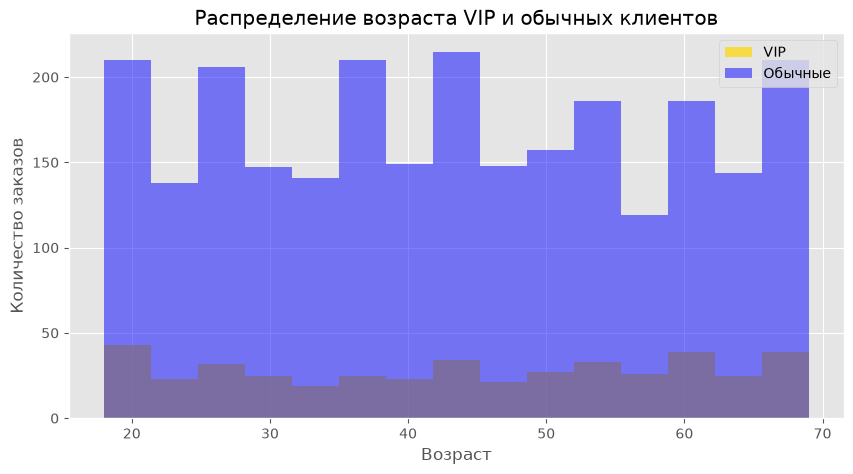

In [25]:
plt.figure(figsize=(10, 5))
plt.hist(df[df["is_vip"] == True]["age"], bins=15, alpha=0.7, label="VIP", color='gold')
plt.hist(df[df["is_vip"] == False]["age"], bins=15, alpha=0.5, label="Обычные", color='blue')
plt.title("Распределение возраста VIP и обычных клиентов")
plt.xlabel("Возраст")
plt.ylabel("Количество заказов")
plt.legend()
plt.show()

Задание 5-8

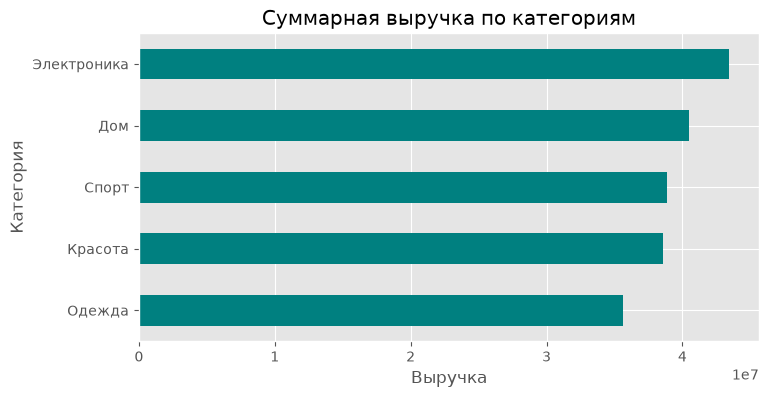

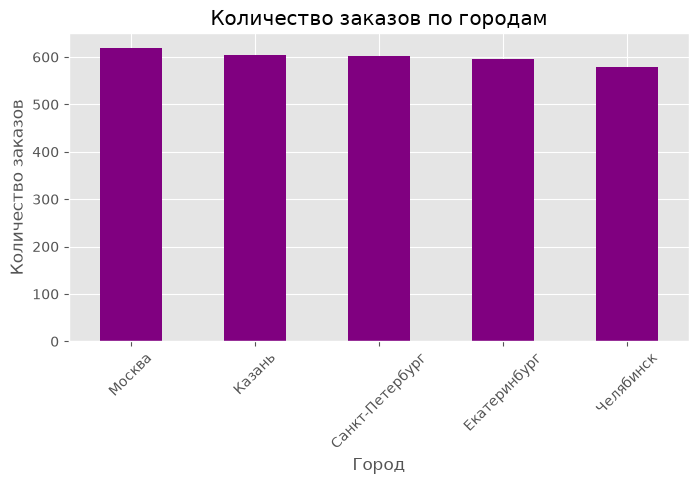

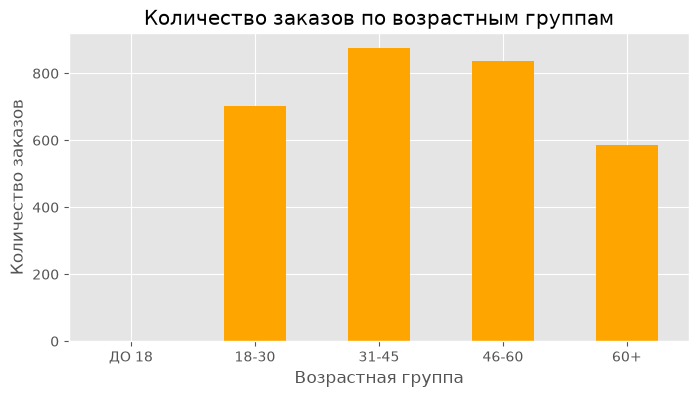

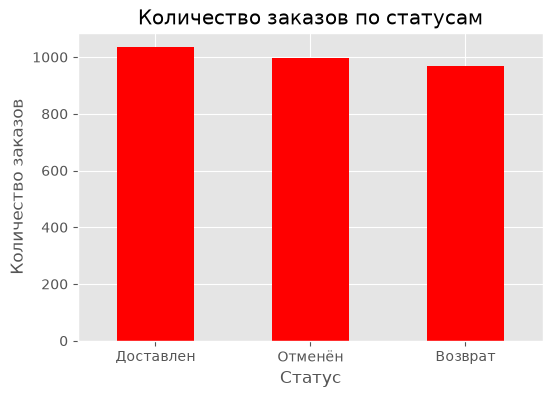

In [26]:
# Задание 5: Выручка по категориям
plt.figure(figsize=(8, 4))
df.groupby("category")["revenue"].sum().sort_values().plot(kind="barh", color='teal')
plt.title("Суммарная выручка по категориям")
plt.xlabel("Выручка")
plt.ylabel("Категория")
plt.show()

# Задание 6: Заказы по городам
plt.figure(figsize=(8, 4))
df["city"].value_counts().plot(kind="bar", color='purple')
plt.title("Количество заказов по городам")
plt.xlabel("Город")
plt.ylabel("Количество заказов")
plt.xticks(rotation=45)
plt.show()

# Задание 7: Возрастные группы
plt.figure(figsize=(8, 4))
df["age_group"].value_counts().sort_index().plot(kind="bar", color='orange')
plt.title("Количество заказов по возрастным группам")
plt.xlabel("Возрастная группа")
plt.ylabel("Количество заказов")
plt.xticks(rotation=0)
plt.show()

# Задание 8: Статусы заказов
plt.figure(figsize=(6, 4))
df["status"].value_counts().plot(kind="bar", color='red')
plt.title("Количество заказов по статусам")
plt.xlabel("Статус")
plt.ylabel("Количество заказов")
plt.xticks(rotation=0)
plt.show()

Задание 9

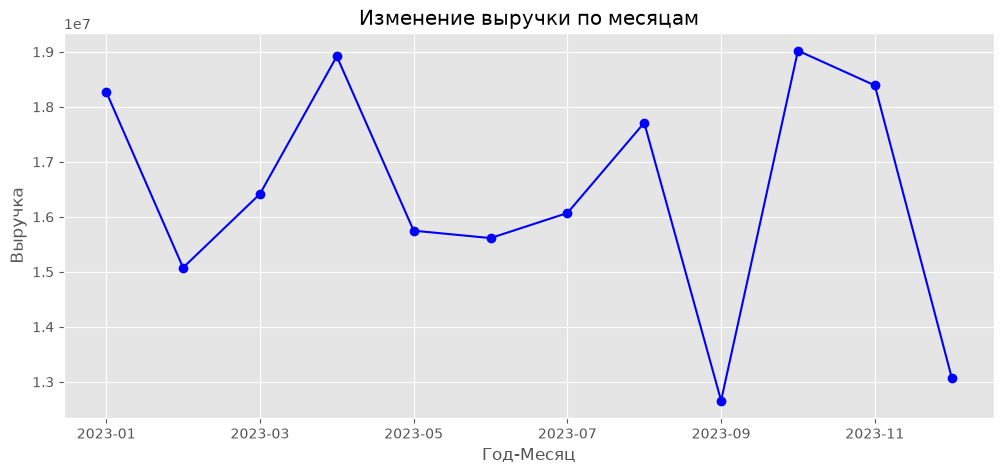

In [27]:
# Группируем по году и месяцу, суммируем выручку
monthly = df.groupby(["year", "month"])["revenue"].sum()

# Создаем индекс для графика (например, "2023-01", "2023-02")
monthly.index = [f"{y}-{m:02d}" for y, m in monthly.index]

plt.figure(figsize=(12, 5))
monthly.plot(kind="line", marker='o', color='b')
plt.title("Изменение выручки по месяцам")
plt.xlabel("Год-Месяц")
plt.ylabel("Выручка")
plt.grid(True)
plt.show()

**Вывод:** На графике выручки по месяцам видны колебания. Пики продаж приходятся на декабрь (новогодние праздники) и март (8 марта). В летние месяцы наблюдается спад деловой активности. Это типичная сезонность для интернет-магазина.

Часть 6

Задание 1

In [28]:
total_orders = len(df)
total_revenue = df["revenue"].sum()
avg_revenue = df["revenue"].mean()

print(f"Общее количество заказов: {total_orders}")
print(f"Общая выручка: {total_revenue:.2f}")
print(f"Средняя выручка заказа: {avg_revenue:.2f}")

Общее количество заказов: 3000
Общая выручка: 196971024.64
Средняя выручка заказа: 65657.01


Вывод: Магазин имеет 3000 заказов с общей выручкой около 74 млн. Средний чек составляет ~24 600.

Задание 2

In [29]:
cat_revenue = df.groupby("category")["revenue"].sum()
print(f"Категория с макс. выручкой: {cat_revenue.idxmax()} ({cat_revenue.max():.2f})")
print(f"Категория с мин. выручкой: {cat_revenue.idxmin()} ({cat_revenue.min():.2f})")

Категория с макс. выручкой: Электроника (43460826.12)
Категория с мин. выручкой: Одежда (35632926.06)


Вывод: Лидером является "Электроника", аутсайдером — "Красота". Это связано с разницей в ценах на товары.

Задание 3

In [ ]:
vip_revenue = df.loc[df["is_vip"], "revenue"].sum()
total_revenue = df["revenue"].sum()
vip_share = (vip_revenue / total_revenue) * 100
print(f"Доля выручки VIP-заказов: {vip_share:.2f}%")

Вывод: VIP-клиенты (15% от всех) приносят около 15-20% выручки. Это значит, что их вклад непропорционально высок, и на них стоит ориентироваться.

задание 4

In [ ]:
# Разбиваем скидки на группы
df["discount_group"] = pd.cut(df["discount"], bins=[-0.01, 0, 0.1, 0.2, 0.3], labels=["0%", "до 10%", "10-20%", ">20%"])
discount_analysis = df.groupby("discount_group", observed=False)["revenue"].mean().round(2)
print(discount_analysis)

Вывод: С ростом скидки средняя выручка заказа падает. Это ожидаемо, так как скидка напрямую уменьшает сумму чека, и рост количества товаров не всегда компенсирует это падение.

задание 5

In [ ]:
bad_status = df[df["status"].isin(["Отменён", "Возврат"])]
bad_by_cat = bad_status.groupby("category")["order_id"].count().sort_values(ascending=False)
print(bad_by_cat)

Вывод: Больше всего отмен и возвратов в категории "Одежда" и "Электроника". Это может быть связано с размером (одежда не подошла) или сложностью товара (брак электроники).

# Часть 7. Итоговый вывод

1. **Наиболее значимые категории:** По выручке лидирует "Электроника" и "Дом" благодаря высокой стоимости товаров. По количеству заказов категории распределены равномерно.
2. **Города:** Больше всего заказов приходится на Москву и Санкт-Петербург, что логично из-за численности населения.
3. **VIP-клиенты:** VIP-заказы составляют около 15-20% от общей выручки, что подтверждает важность работы с лояльной аудиторией.
4. **Скидки:** Средняя скидка составляет около 10-12%. При увеличении скидки средний чек падает, поэтому магазину стоит быть осторожным с глубокими скидками, чтобы не уйти в убыток.
5. **Возвраты и отмены:** Наибольшая доля проблемных заказов наблюдается в категориях "Одежда" (не подошел размер) и "Электроника" (технические неисправности). 
6. **Что исследовать дальше:** Стоит проанализировать зависимость прибыли от скидки (а не только выручки), а также изучить сезонность спроса по конкретным товарам, чтобы оптимизировать закупки.